In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime
import holidays
from google.colab import drive
drive.mount('/content/drive')

import plotly as py
import plotly.express as px
from plotly.offline import init_notebook_mode, iplot, plot
init_notebook_mode(connected=True)
import plotly.graph_objs as go


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
data = pd.read_csv(r'/content/drive/MyDrive/2023 예측 프로젝트 1차/train.csv')

In [3]:
data['일시'] = pd.date_range(pd.to_datetime('2018-01-01'), pd.to_datetime('2021-12-31') , freq='D')

#data = data.drop(789)
#data = data.reset_index(drop=True)


In [4]:
df1 = data[['일시','광진구']]
df2 =  data[['일시','동대문구']]
df3 =  data[['일시','성동구']]
df4 =  data[['일시','중랑구']]

In [5]:
dt2018 = pd.read_csv(r'/content/drive/MyDrive/2023 예측 프로젝트 1차/일별평균대기오염도_2018.csv',encoding = "cp949")
dt2019 = pd.read_csv(r'/content/drive/MyDrive/2023 예측 프로젝트 1차/일별평균대기오염도_2019.csv',encoding = "cp949")
dt2020 = pd.read_csv(r'/content/drive/MyDrive/2023 예측 프로젝트 1차/일별평균대기오염도_2020.csv',encoding = "cp949")
dt2021 = pd.read_csv(r'/content/drive/MyDrive/2023 예측 프로젝트 1차/일별평균대기오염도_2021.csv',encoding = "cp949")


In [6]:
def misae(df):
  df.loc[df['미세먼지농도(㎍/㎥)'] <= 15 , '미세먼지농도(㎍/㎥)'] = 0
  df.loc[((df['미세먼지농도(㎍/㎥)'] > 15) & (df['미세먼지농도(㎍/㎥)'] <= 35)), '미세먼지농도(㎍/㎥)'] = 1
  df.loc[((df['미세먼지농도(㎍/㎥)'] > 35) & (df['미세먼지농도(㎍/㎥)'] <= 75)), '미세먼지농도(㎍/㎥)'] = 2
  df.loc[df['미세먼지농도(㎍/㎥)'] > 75 , '미세먼지농도(㎍/㎥)'] = 3
  df.loc[df['초미세먼지농도(㎍/㎥)'] <= 30 , '초미세먼지농도(㎍/㎥)'] = 0
  df.loc[((df['초미세먼지농도(㎍/㎥)'] > 30) & (df['초미세먼지농도(㎍/㎥)'] <= 80)), '초미세먼지농도(㎍/㎥)'] = 1
  df.loc[((df['초미세먼지농도(㎍/㎥)'] > 80) & (df['초미세먼지농도(㎍/㎥)'] <= 150)), '초미세먼지농도(㎍/㎥)'] = 2
  df.loc[df['초미세먼지농도(㎍/㎥)'] > 150 , '초미세먼지농도(㎍/㎥)'] = 3

In [7]:
def makedf(dt2018,dt2019,dt2020,dt2021,df1,cond):
  df2018_1 = dt2018.loc[dt2018['측정소명']==cond]
  df2019_1 = dt2019.loc[dt2019['측정소명']==cond]
  df2020_1 = dt2020.loc[dt2020['측정소명']==cond]
  df2021_1 = dt2021.loc[dt2021['측정소명']==cond]
  df1_1 = pd.concat([df2018_1,df2019_1,df2020_1,df2021_1])
  df1_1 = df1_1[['측정일시','미세먼지농도(㎍/㎥)','초미세먼지농도(㎍/㎥)']]
  df1_1.columns = df1_1.columns.str.replace('측정일시', '일시')
  df1_1['일시'] = pd.date_range(pd.to_datetime('2018-01-01'), pd.to_datetime('2021-12-31') , freq='D')
  newdf = df1.merge(df1_1,how='left',on='일시')
  newdf['대여량'] = newdf[cond]
  newdf.drop(cond,axis=1,inplace = True)
  return newdf

In [8]:
def configure_plotly_browser_state():
  import IPython
  display(IPython.core.display.HTML('''
        <script src="/static/components/requirejs/require.js"></script>
        <script>
          requirejs.config({
            paths: {
              base: '/static/base',
              plotly: 'https://cdn.plot.ly/plotly-latest.min.js?noext',
            },
          });
        </script>
        '''))

In [9]:
newdf1 = makedf(dt2018,dt2019,dt2020,dt2021,df1,'광진구')
newdf2 = makedf(dt2018,dt2019,dt2020,dt2021,df2,'동대문구')
newdf3 = makedf(dt2018,dt2019,dt2020,dt2021,df3,'성동구')
newdf4 = makedf(dt2018,dt2019,dt2020,dt2021,df4,'중랑구')

/usr/local/lib/python3.9/dist-packages/pandas/plotting/_matplotlib/core.py:1114: UserWarning:

No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored



<Axes: xlabel='초미세먼지농도(㎍/㎥)', ylabel='대여량'>

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 48120 (\N{HANGUL SYLLABLE MI}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 49464 (\N{HANGUL SYLLABLE SE}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 47676 (\N{HANGUL SYLLABLE MEON}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 45453 (\N{HANGUL SYLLABLE NONG}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 46020 (\N{HANGUL SYLLABLE DO}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 13197 (\N{SQUARE MU G}) missing from cur

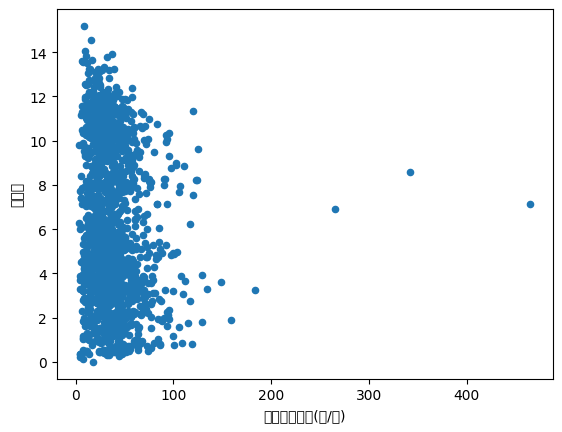

/usr/local/lib/python3.9/dist-packages/IPython/core/pylabtools.py:151: UserWarning:

Glyph 52488 (\N{HANGUL SYLLABLE CO}) missing from current font.



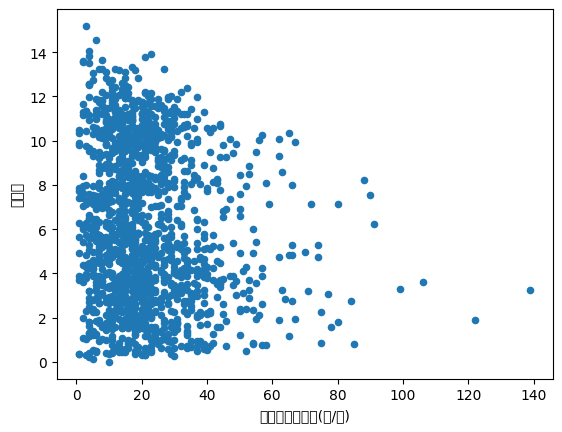

In [11]:
newdf1.plot.scatter('미세먼지농도(㎍/㎥)','대여량')
newdf1.plot.scatter('초미세먼지농도(㎍/㎥)','대여량')

In [12]:
trace1 = go.Scatter(
    x = newdf1['일시'],
    y = newdf1['초미세먼지농도(㎍/㎥)'],
    mode = 'lines',
    marker = dict(color = px.colors.qualitative.Plotly[0]),
)

trace2 = go.Scatter(
    x = newdf2['일시'],
    y = newdf2['초미세먼지농도(㎍/㎥)'],
    mode = 'lines',
    marker = dict(color = px.colors.qualitative.Plotly[1]),
)

trace3 = go.Scatter(
    x = newdf3['일시'],
    y = newdf3['초미세먼지농도(㎍/㎥)'],
    mode = 'lines',
    marker = dict(color = px.colors.qualitative.Plotly[2]),
)

trace4 = go.Scatter(
    x = newdf4['일시'],
    y = newdf4['초미세먼지농도(㎍/㎥)'],
    mode = 'lines',
    marker = dict(color = px.colors.qualitative.Plotly[3]),
)

configure_plotly_browser_state()
data = [trace1, trace2, trace3, trace4]
layout = dict(title='Checking the chomisae', xaxis=dict(title='Year'))
fig = dict(data=data, layout=layout)
iplot(fig)

In [13]:
trace1 = go.Scatter(
    x = newdf1['일시'],
    y = newdf1['미세먼지농도(㎍/㎥)'],
    mode = 'lines',
    marker = dict(color = px.colors.qualitative.Plotly[0]),
)

trace2 = go.Scatter(
    x = newdf2['일시'],
    y = newdf2['미세먼지농도(㎍/㎥)'],
    mode = 'lines',
    marker = dict(color = px.colors.qualitative.Plotly[1]),
)

trace3 = go.Scatter(
    x = newdf3['일시'],
    y = newdf3['미세먼지농도(㎍/㎥)'],
    mode = 'lines',
    marker = dict(color = px.colors.qualitative.Plotly[2]),
)

trace4 = go.Scatter(
    x = newdf4['일시'],
    y = newdf4['미세먼지농도(㎍/㎥)'],
    mode = 'lines',
    marker = dict(color = px.colors.qualitative.Plotly[3]),
)

configure_plotly_browser_state()
data = [trace1, trace2, trace3, trace4]
layout = dict(title='Checking the misae', xaxis=dict(title='Year'))
fig = dict(data=data, layout=layout)
iplot(fig)

In [14]:
misae(newdf1)
misae(newdf2)
misae(newdf3)
misae(newdf4)

<Axes: title={'center': '대여량'}, xlabel='초미세먼지농도(㎍/㎥)'>

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 45824 (\N{HANGUL SYLLABLE DAE}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 50668 (\N{HANGUL SYLLABLE YEO}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 47049 (\N{HANGUL SYLLABLE RYANG}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 48120 (\N{HANGUL SYLLABLE MI}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 49464 (\N{HANGUL SYLLABLE SE}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 47676 (\N{HANGUL SYLLABLE MEON}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 51648 (\N{HANGUL SYLLABLE JI}) missin

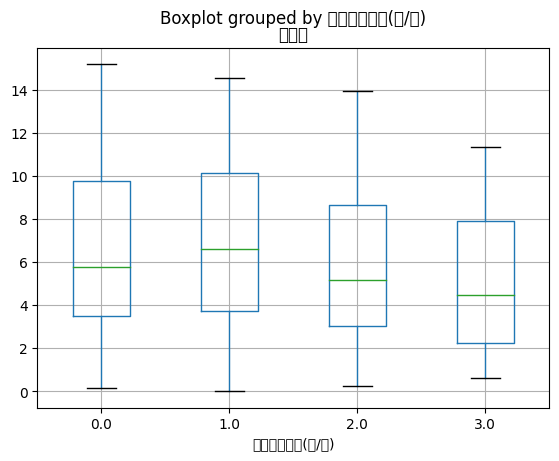

/usr/local/lib/python3.9/dist-packages/IPython/core/pylabtools.py:151: UserWarning:

Glyph 52488 (\N{HANGUL SYLLABLE CO}) missing from current font.



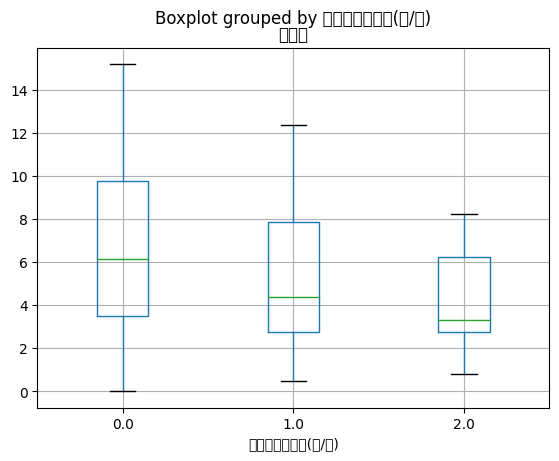

In [15]:
newdf1.boxplot(column='대여량',by='미세먼지농도(㎍/㎥)')
newdf1.boxplot(column='대여량',by='초미세먼지농도(㎍/㎥)')

<Axes: title={'center': '대여량'}, xlabel='초미세먼지농도(㎍/㎥)'>

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 45824 (\N{HANGUL SYLLABLE DAE}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 50668 (\N{HANGUL SYLLABLE YEO}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 47049 (\N{HANGUL SYLLABLE RYANG}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 48120 (\N{HANGUL SYLLABLE MI}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 49464 (\N{HANGUL SYLLABLE SE}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 47676 (\N{HANGUL SYLLABLE MEON}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 51648 (\N{HANGUL SYLLABLE JI}) missin

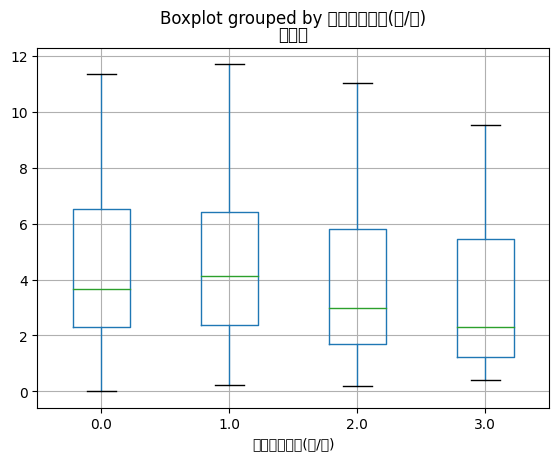

/usr/local/lib/python3.9/dist-packages/IPython/core/pylabtools.py:151: UserWarning:

Glyph 52488 (\N{HANGUL SYLLABLE CO}) missing from current font.



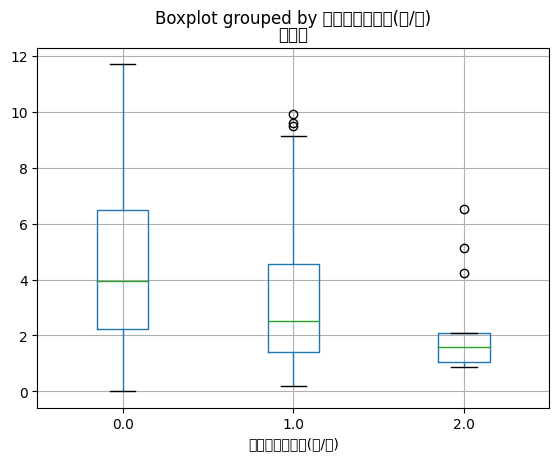

In [16]:
newdf2.boxplot(column='대여량',by='미세먼지농도(㎍/㎥)')
newdf2.boxplot(column='대여량',by='초미세먼지농도(㎍/㎥)')

<Axes: title={'center': '대여량'}, xlabel='초미세먼지농도(㎍/㎥)'>

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 45824 (\N{HANGUL SYLLABLE DAE}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 50668 (\N{HANGUL SYLLABLE YEO}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 47049 (\N{HANGUL SYLLABLE RYANG}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 48120 (\N{HANGUL SYLLABLE MI}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 49464 (\N{HANGUL SYLLABLE SE}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 47676 (\N{HANGUL SYLLABLE MEON}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 51648 (\N{HANGUL SYLLABLE JI}) missin

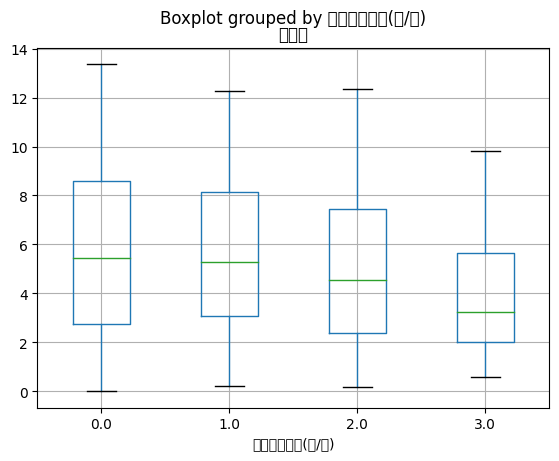

/usr/local/lib/python3.9/dist-packages/IPython/core/pylabtools.py:151: UserWarning:

Glyph 52488 (\N{HANGUL SYLLABLE CO}) missing from current font.



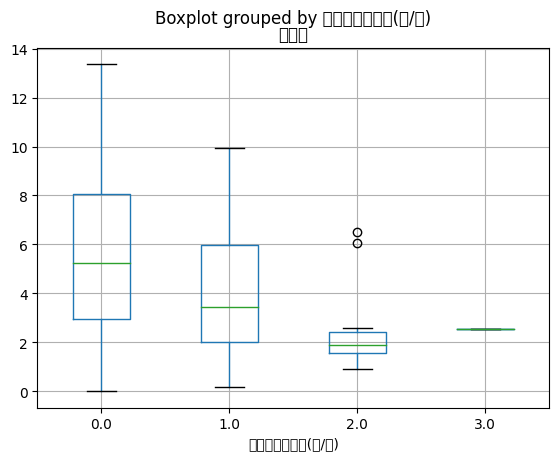

In [17]:
newdf3.boxplot(column='대여량',by='미세먼지농도(㎍/㎥)')
newdf3.boxplot(column='대여량',by='초미세먼지농도(㎍/㎥)')

<Axes: title={'center': '대여량'}, xlabel='초미세먼지농도(㎍/㎥)'>

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 45824 (\N{HANGUL SYLLABLE DAE}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 50668 (\N{HANGUL SYLLABLE YEO}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 47049 (\N{HANGUL SYLLABLE RYANG}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 48120 (\N{HANGUL SYLLABLE MI}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 49464 (\N{HANGUL SYLLABLE SE}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 47676 (\N{HANGUL SYLLABLE MEON}) missing from current font.

/usr/local/lib/python3.9/dist-packages/IPython/core/events.py:89: UserWarning:

Glyph 51648 (\N{HANGUL SYLLABLE JI}) missin

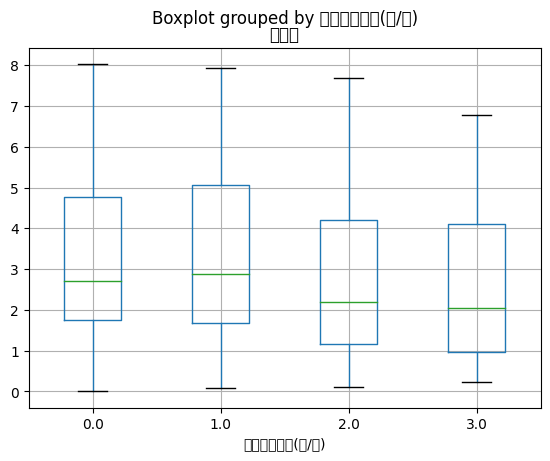

/usr/local/lib/python3.9/dist-packages/IPython/core/pylabtools.py:151: UserWarning:

Glyph 52488 (\N{HANGUL SYLLABLE CO}) missing from current font.



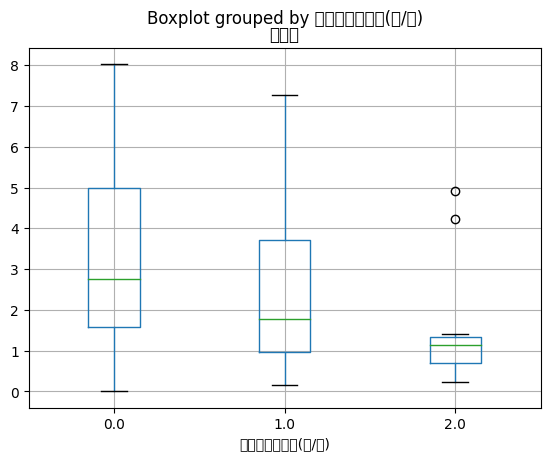

In [18]:
newdf4.boxplot(column='대여량',by='미세먼지농도(㎍/㎥)')
newdf4.boxplot(column='대여량',by='초미세먼지농도(㎍/㎥)')

In [19]:
trace1 = go.Scatter(
    x = newdf1['일시'],
    y = newdf1['대여량'],
    mode = 'lines',
    marker = dict(color = px.colors.qualitative.Plotly[0]),
)

trace2 = go.Scatter(
    x = newdf2['일시'],
    y = newdf2['대여량'],
    mode = 'lines',
    marker = dict(color = px.colors.qualitative.Plotly[1]),
)

trace3 = go.Scatter(
    x = newdf3['일시'],
    y = newdf3['대여량'],
    mode = 'lines',
    marker = dict(color = px.colors.qualitative.Plotly[2]),
)

trace4 = go.Scatter(
    x = newdf4['일시'],
    y = newdf4['대여량'],
    mode = 'lines',
    marker = dict(color = px.colors.qualitative.Plotly[3]),
)

configure_plotly_browser_state()
data = [trace1, trace2, trace3, trace4]
layout = dict(title='Checking the total time series', xaxis=dict(title='Year'))
fig = dict(data=data, layout=layout)
iplot(fig)

In [21]:
def getmed(df):
  for i in range(4):
    print('미세먼지 ' + str(i),':',df.loc[df['미세먼지농도(㎍/㎥)'] == i]['대여량'].median())
  for i in range(4):
    print('초미세먼지 ' + str(i),':',df.loc[df['미세먼지농도(㎍/㎥)'] == i]['대여량'].median())


In [22]:
getmed(newdf1)

미세먼지 0 : 5.786
미세먼지 1 : 6.628
미세먼지 2 : 5.163
미세먼지 3 : 4.471
초미세먼지 0 : 5.786
초미세먼지 1 : 6.628
초미세먼지 2 : 5.163
초미세먼지 3 : 4.471


In [23]:
getmed(newdf2)

미세먼지 0 : 3.646
미세먼지 1 : 4.1129999999999995
미세먼지 2 : 2.995
미세먼지 3 : 2.304
초미세먼지 0 : 3.646
초미세먼지 1 : 4.1129999999999995
초미세먼지 2 : 2.995
초미세먼지 3 : 2.304


In [24]:
getmed(newdf3)

미세먼지 0 : 5.458
미세먼지 1 : 5.302
미세먼지 2 : 4.568
미세먼지 3 : 3.2270000000000003
초미세먼지 0 : 5.458
초미세먼지 1 : 5.302
초미세먼지 2 : 4.568
초미세먼지 3 : 3.2270000000000003


In [25]:
getmed(newdf4)

미세먼지 0 : 2.699
미세먼지 1 : 2.8760000000000003
미세먼지 2 : 2.1959999999999997
미세먼지 3 : 2.045
초미세먼지 0 : 2.699
초미세먼지 1 : 2.8760000000000003
초미세먼지 2 : 2.1959999999999997
초미세먼지 3 : 2.045


In [29]:
data= [newdf1,newdf2,newdf3,newdf4]

for df in data:
  standard = df.loc[df['미세먼지농도(㎍/㎥)'] == 1]['대여량'].median()
  for i in range(4):
    df.loc[df['미세먼지농도(㎍/㎥)'] == i, '대여량'] = df.loc[df['미세먼지농도(㎍/㎥)'] == i]['대여량'] + (standard - df.loc[df['미세먼지농도(㎍/㎥)'] == i]['대여량'].median())

In [30]:
getmed(newdf1)

미세먼지 0 : 6.628
미세먼지 1 : 6.628
미세먼지 2 : 6.628
미세먼지 3 : 6.628
초미세먼지 0 : 6.628
초미세먼지 1 : 6.628
초미세먼지 2 : 6.628
초미세먼지 3 : 6.628


In [ ]:
newdf1

In [ ]:
newdf1['미세먼지농도(㎍/㎥)'].value_counts()

In [ ]:
newdf2['미세먼지농도(㎍/㎥)'].value_counts()

In [ ]:
newdf3['미세먼지농도(㎍/㎥)'].value_counts()

In [ ]:
newdf4['미세먼지농도(㎍/㎥)'].value_counts()